# 06 · Fine-tuning del modelo de keypoints con experimento de congelación de capas

**Objetivo:** adaptar el modelo base de keypoints (entrenado con SoccerNet) al dominio de la Bundesliga mediante fine-tuning, comparando distintas estrategias de congelación de capas para determinar cuál generaliza mejor con un dataset reducido.

**Contexto:** se dispone de 96 imágenes de entrenamiento propias revisadas manualmente. Con tan pocos datos, el grado de congelación de capas es clave: congelar más capas reduce el riesgo de sobreajuste pero limita la adaptación. Se comparan tres configuraciones (B, C, D) a 640px. La mejor se reentrenará después a 1280px (modelo E) para evaluar el efecto de la resolución.

**Configuraciones:**
- **A:** modelo base sin fine-tuning (ya entrenado, sirve de referencia)
- **B:** fine-tuning completo (freeze=0)
- **C:** backbone congelado (freeze=10)
- **D:** solo cabeza (freeze=22)

**Entrada:** modelo base `keypoints_base.pt` y dataset `data/bundesliga_keypoints/`.

**Salida:** modelos `keypoints_ft_B.pt`, `keypoints_ft_C.pt`, `keypoints_ft_D.pt`.

In [1]:
import torch
from ultralytics import YOLO
from pathlib import Path
import shutil

REPO_ROOT = Path("../..").resolve()
BASE_MODEL = REPO_ROOT / "models" / "keypoints_base.pt"
DATA_YAML = REPO_ROOT / "data" / "bundesliga_keypoints" / "data.yaml"
MODELS_DIR = REPO_ROOT / "models"

print(f"Modelo base: {BASE_MODEL.exists()}")
print(f"Dataset: {DATA_YAML.exists()}")
print(f"GPU: {torch.cuda.get_device_name(0)}")

# Hiperparámetros comunes (pocas épocas y patience bajo por dataset pequeño)
EPOCHS = 25
PATIENCE = 5
IMGSZ = 640
BATCH = 8

Modelo base: True
Dataset: True
GPU: NVIDIA GeForce RTX 2060


## Modelo B — Fine-tuning completo (freeze=0)

Se afinan todas las capas del modelo. Máxima capacidad de adaptación al nuevo dominio, pero mayor riesgo de sobreajuste con pocos datos.

In [2]:
model_B = YOLO(str(BASE_MODEL))

results_B = model_B.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=0,
    project=str(REPO_ROOT / "runs" / "pose" / "finetuning"),
    name="ft_B_completo",
    patience=PATIENCE,
    freeze=0,
    save=True,
    plots=True,
    workers=0
)

shutil.copy2(Path(results_B.save_dir) / "weights" / "best.pt", MODELS_DIR / "keypoints_ft_B.pt")
print("Modelo B guardado")

New https://pypi.org/project/ultralytics/8.4.62 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.53  Python-3.13.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\bundesliga_keypoints\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=0, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Users

## Modelo C — Backbone congelado (freeze=10)

Se congelan las primeras 10 capas (el backbone, extractor de características aprendido en SoccerNet) y solo se afinan el cuello y la cabeza. Equilibrio entre adaptación y resistencia al sobreajuste.

In [3]:
model_C = YOLO(str(BASE_MODEL))

results_C = model_C.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=0,
    project=str(REPO_ROOT / "runs" / "pose" / "finetuning"),
    name="ft_C_backbone",
    patience=PATIENCE,
    freeze=10,
    save=True,
    plots=True,
    workers=0
)

shutil.copy2(Path(results_C.save_dir) / "weights" / "best.pt", MODELS_DIR / "keypoints_ft_C.pt")
print("Modelo C guardado")

New https://pypi.org/project/ultralytics/8.4.62 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.53  Python-3.13.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\bundesliga_keypoints\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\User

## Modelo D — Solo cabeza (freeze=22)

Se congela casi toda la red (backbone y cuello) y solo se afina la cabeza de pose. Mínima capacidad de cambio, máxima resistencia al sobreajuste. Puede resultar demasiado rígido si el dominio difiere mucho.

In [4]:
model_D = YOLO(str(BASE_MODEL))

results_D = model_D.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=0,
    project=str(REPO_ROOT / "runs" / "pose" / "finetuning"),
    name="ft_D_cabeza",
    patience=PATIENCE,
    freeze=22,
    save=True,
    plots=True,
    workers=0
)

shutil.copy2(Path(results_D.save_dir) / "weights" / "best.pt", MODELS_DIR / "keypoints_ft_D.pt")
print("Modelo D guardado")

New https://pypi.org/project/ultralytics/8.4.62 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.53  Python-3.13.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\bundesliga_keypoints\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=22, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\User

In [5]:
# Resumen rápido de las métricas de validación de cada modelo
print("Resumen de fine-tuning (Pose mAP50 en validación):\n")
for nombre, res in [("B (completo)", results_B), ("C (backbone)", results_C), ("D (cabeza)", results_D)]:
    # La métrica final está en los resultados del entrenamiento
    print(f"  {nombre}: ver runs/pose/finetuning/{Path(res.save_dir).name}")

Resumen de fine-tuning (Pose mAP50 en validación):

  B (completo): ver runs/pose/finetuning/ft_B_completo
  C (backbone): ver runs/pose/finetuning/ft_C_backbone
  D (cabeza): ver runs/pose/finetuning/ft_D_cabeza


In [6]:
# Modelo E: la mejor config (C, freeze=10) a 1280px
model_E = YOLO(str(BASE_MODEL))

results_E = model_E.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=1280,
    batch=2,          # bajado por la resolución alta
    device=0,
    project=str(REPO_ROOT / "runs" / "pose" / "finetuning"),
    name="ft_E_backbone_1280",
    patience=PATIENCE,
    freeze=10,         # misma congelación que C
    save=True,
    plots=True,
    workers=0,
    amp=True
)

shutil.copy2(Path(results_E.save_dir) / "weights" / "best.pt", MODELS_DIR / "keypoints_ft_E.pt")
print("Modelo E guardado")

New https://pypi.org/project/ultralytics/8.4.62 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.53  Python-3.13.13 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\data\bundesliga_keypoints\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=C:\Use

## Comparativa del experimento de congelación de capas

Se comparan las cinco configuraciones evaluadas sobre el conjunto de validación de Bundesliga. El modelo A es el base de SoccerNet sin fine-tuning (referencia); B, C y D varían el grado de congelación a 640px; E reentrena la mejor configuración (C) a 1280px.

In [7]:
# Resultados del experimento de congelación de capas (validación Bundesliga)
resultados_ft = {
    "A (base SoccerNet, sin FT)":   {"freeze": "-",  "imgsz": 640,  "mAP50": None,  "mAP50_95": None},
    "B (FT completo, freeze=0)":    {"freeze": 0,    "imgsz": 640,  "mAP50": 0.940, "mAP50_95": 0.620},
    "C (FT backbone, freeze=10)":   {"freeze": 10,   "imgsz": 640,  "mAP50": 0.951, "mAP50_95": 0.679},
    "D (FT cabeza, freeze=22)":     {"freeze": 22,   "imgsz": 640,  "mAP50": 0.949, "mAP50_95": 0.642},
    "E (FT backbone, 1280px)":      {"freeze": 10,   "imgsz": 1280, "mAP50": 0.718, "mAP50_95": 0.428},
}

print("EXPERIMENTO DE CONGELACIÓN DE CAPAS (Pose, validación Bundesliga)\n")
print(f"{'Modelo':<32} {'freeze':>7} {'imgsz':>6} {'mAP50':>8} {'mAP50-95':>10}")
print("-" * 68)
for nombre, r in resultados_ft.items():
    m50 = f"{r['mAP50']:.3f}" if r['mAP50'] is not None else "  -"
    m5095 = f"{r['mAP50_95']:.3f}" if r['mAP50_95'] is not None else "  -"
    print(f"{nombre:<32} {str(r['freeze']):>7} {r['imgsz']:>6} {m50:>8} {m5095:>10}")
print("-" * 68)
print("\nMejor configuración: C (fine-tuning con backbone congelado, 640px)")
print("  - Mayor mAP50-95 (0.679), la métrica más relevante para la precisión de la homografía")
print("  - Confirma que congelar el backbone generaliza mejor con datasets pequeños")
print("  - La alta resolución (E) empeora: los keypoints no son objetos pequeños como el balón")

EXPERIMENTO DE CONGELACIÓN DE CAPAS (Pose, validación Bundesliga)

Modelo                            freeze  imgsz    mAP50   mAP50-95
--------------------------------------------------------------------
A (base SoccerNet, sin FT)             -    640        -          -
B (FT completo, freeze=0)              0    640    0.940      0.620
C (FT backbone, freeze=10)            10    640    0.951      0.679
D (FT cabeza, freeze=22)              22    640    0.949      0.642
E (FT backbone, 1280px)               10   1280    0.718      0.428
--------------------------------------------------------------------

Mejor configuración: C (fine-tuning con backbone congelado, 640px)
  - Mayor mAP50-95 (0.679), la métrica más relevante para la precisión de la homografía
  - Confirma que congelar el backbone generaliza mejor con datasets pequeños
  - La alta resolución (E) empeora: los keypoints no son objetos pequeños como el balón


Figura guardada en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\comparativa_congelacion_keypoints.png


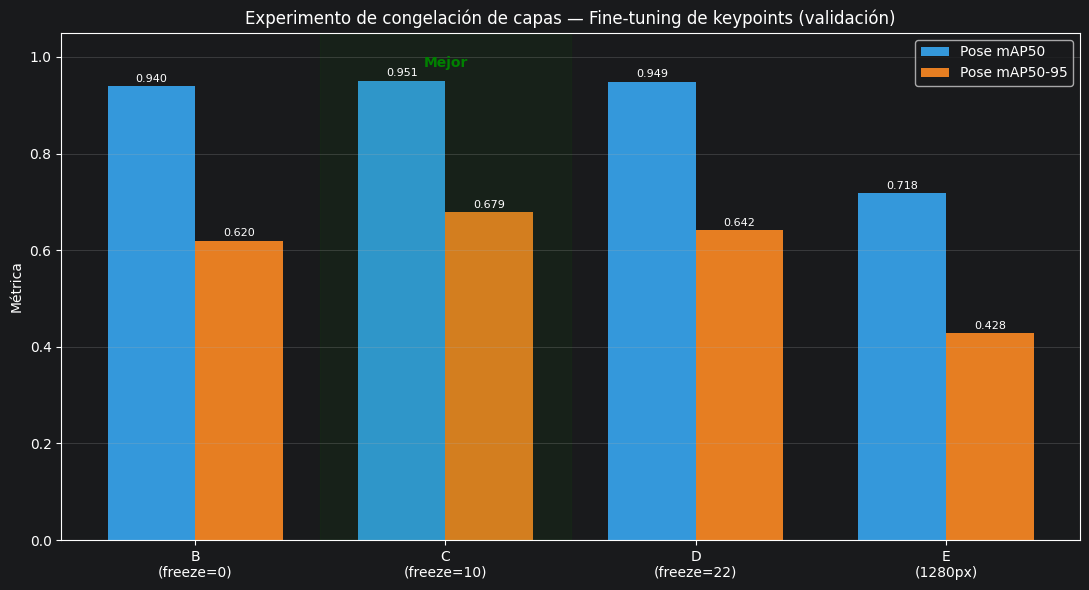

In [9]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

REPO_ROOT = Path("../..").resolve()

# Solo los modelos con métricas (B, C, D, E)
modelos = ["B\n(freeze=0)", "C\n(freeze=10)", "D\n(freeze=22)", "E\n(1280px)"]
map50 = [0.940, 0.951, 0.949, 0.718]
map5095 = [0.620, 0.679, 0.642, 0.428]

x = np.arange(len(modelos))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(x - width/2, map50, width, label="Pose mAP50", color="#3498db")
b2 = ax.bar(x + width/2, map5095, width, label="Pose mAP50-95", color="#e67e22")

ax.set_ylabel("Métrica")
ax.set_title("Experimento de congelación de capas — Fine-tuning de keypoints (validación)")
ax.set_xticks(x)
ax.set_xticklabels(modelos)
ax.legend()
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)

# Resaltar el ganador (C)
ax.axvspan(0.5, 1.5, alpha=0.08, color="green")
ax.annotate("Mejor", xy=(1, 0.98), ha="center", fontsize=10, fontweight="bold", color="green")

for bars in [b1, b2]:
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)

plt.tight_layout()
output_fig = REPO_ROOT / "outputs" / "comparativa_congelacion_keypoints.png"
output_fig.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(str(output_fig), dpi=100, bbox_inches="tight")
print(f"Figura guardada en: {output_fig}")
plt.show()